In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import datasets, layers, models
from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)
print("Librerías cargadas correctamente.")

TensorFlow: 2.21.0
Librerías cargadas correctamente.


In [2]:
# Cargar el conjunto de imágenes CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Nombres de las 10 categorías
class_names = [
    'Avión', 'Auto', 'Pájaro', 'Gato', 'Ciervo',
    'Perro', 'Rana', 'Caballo', 'Barco', 'Camión'
]

# Normalizar los píxeles entre 0 y 1
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

# Separar los datos de entrenamiento y validación
train_images, val_images, train_labels, val_labels = train_test_split(
    train_images,
    train_labels,
    test_size=0.2,
    random_state=42
)

print("Entrenamiento:", train_images.shape)
print("Validación:", val_images.shape)
print("Prueba:", test_images.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3817s 22us/step
Entrenamiento: (40000, 32, 32, 3)
Validación: (10000, 32, 32, 3)
Prueba: (10000, 32, 32, 3)


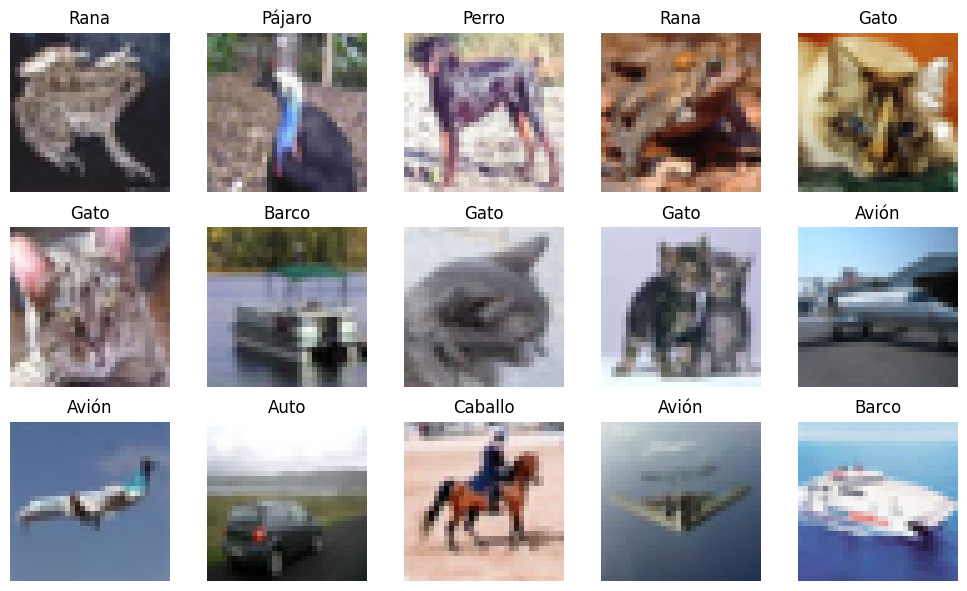

In [3]:
plt.figure(figsize=(10, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(train_images[i])
    plt.title(class_names[int(train_labels[i][0])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_images,
    train_labels,
    epochs=10,
    batch_size=64,
    validation_data=(val_images, val_labels)
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 122ms/step - accuracy: 0.4608 - loss: 1.4879 - val_accuracy: 0.5413 - val_loss: 1.3037
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 115ms/step - accuracy: 0.6154 - loss: 1.0938 - val_accuracy: 0.6440 - val_loss: 1.0192
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 117ms/step - accuracy: 0.6757 - loss: 0.9257 - val_accuracy: 0.6813 - val_loss: 0.9181
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 115ms/step - accuracy: 0.7178 - loss: 0.8076 - val_accuracy: 0.6992 - val_loss: 0.8644
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 88s 125ms/step - accuracy: 0.7523 - loss: 0.7109 - val_accuracy: 0.7141 - val_loss: 0.8253
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 73s 117ms/step - accuracy: 0.7798 - loss: 0.6339 - val_accuracy: 0.7183 - val_loss: 0.8201
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 73s 117ms/step - accuracy: 0.8024 - loss: 0.5611 - val_accuracy: 0.7152 - val_loss: 0.8498
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 73s 117ms/step - accuracy: 0.8274 - loss: 0

In [6]:
test_loss, test_accuracy = model.evaluate(
    test_images,
    test_labels,
    verbose=1
)

print(f"Pérdida en prueba: {test_loss:.4f}")
print(f"Precisión en prueba: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.7086 - loss: 0.9897
Pérdida en prueba: 0.9897
Precisión en prueba: 70.86%


In [7]:
import os

os.makedirs("modelo", exist_ok=True)

model.save_weights("modelo/modelo_cnn_cifar10.weights.h5")

print("Pesos guardados correctamente.")

Pesos guardados correctamente.


In [8]:
from google.colab import files

files.download("modelo/modelo_cnn_cifar10.weights.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

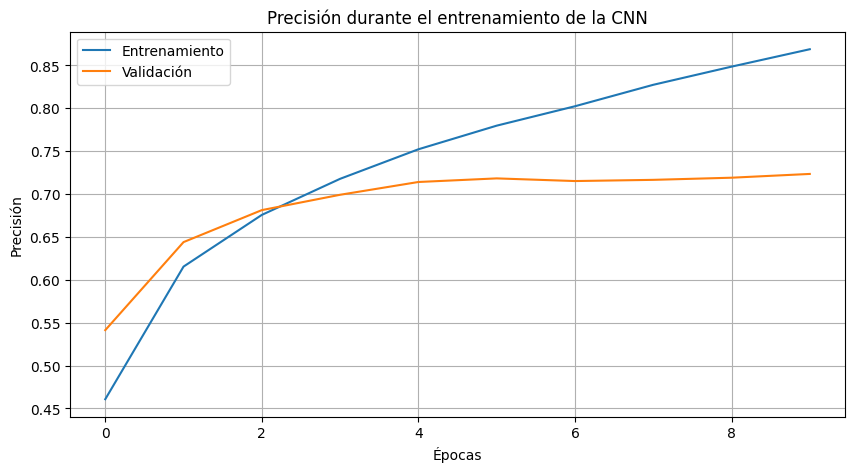

Gráfica guardada correctamente.


In [9]:
import os
import matplotlib.pyplot as plt

# Crear la carpeta de resultados
os.makedirs("resultados", exist_ok=True)

# Gráfica de precisión
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")

plt.title("Precisión durante el entrenamiento de la CNN")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend()
plt.grid(True)

plt.savefig("resultados/entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

print("Gráfica guardada correctamente.")

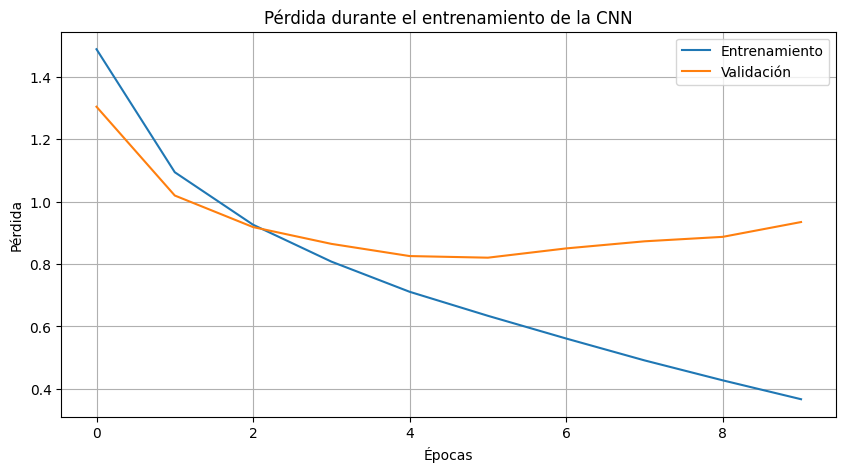

Gráfica de pérdida guardada correctamente.


In [10]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")

plt.title("Pérdida durante el entrenamiento de la CNN")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)

plt.savefig("resultados/perdida.png", dpi=150, bbox_inches="tight")
plt.show()

print("Gráfica de pérdida guardada correctamente.")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step


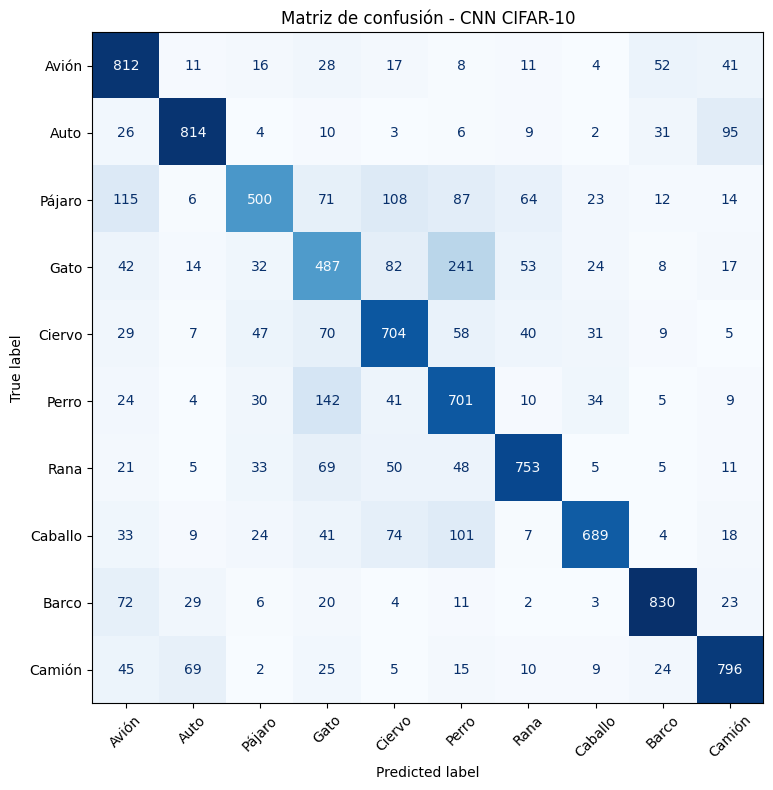

Matriz de confusión guardada correctamente.


In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Obtener predicciones para las imágenes de prueba
predictions = model.predict(test_images, verbose=1)

# Convertir probabilidades en clases
predicted_labels = np.argmax(predictions, axis=1)

# Convertir las etiquetas reales a una lista de clases
true_labels = test_labels.flatten()

# Calcular la matriz de confusión
cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=list(range(10))
)

# Visualizar la matriz
fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

plt.title("Matriz de confusión - CNN CIFAR-10")
plt.tight_layout()

plt.savefig(
    "resultados/matriz_confusion.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Matriz de confusión guardada correctamente.")

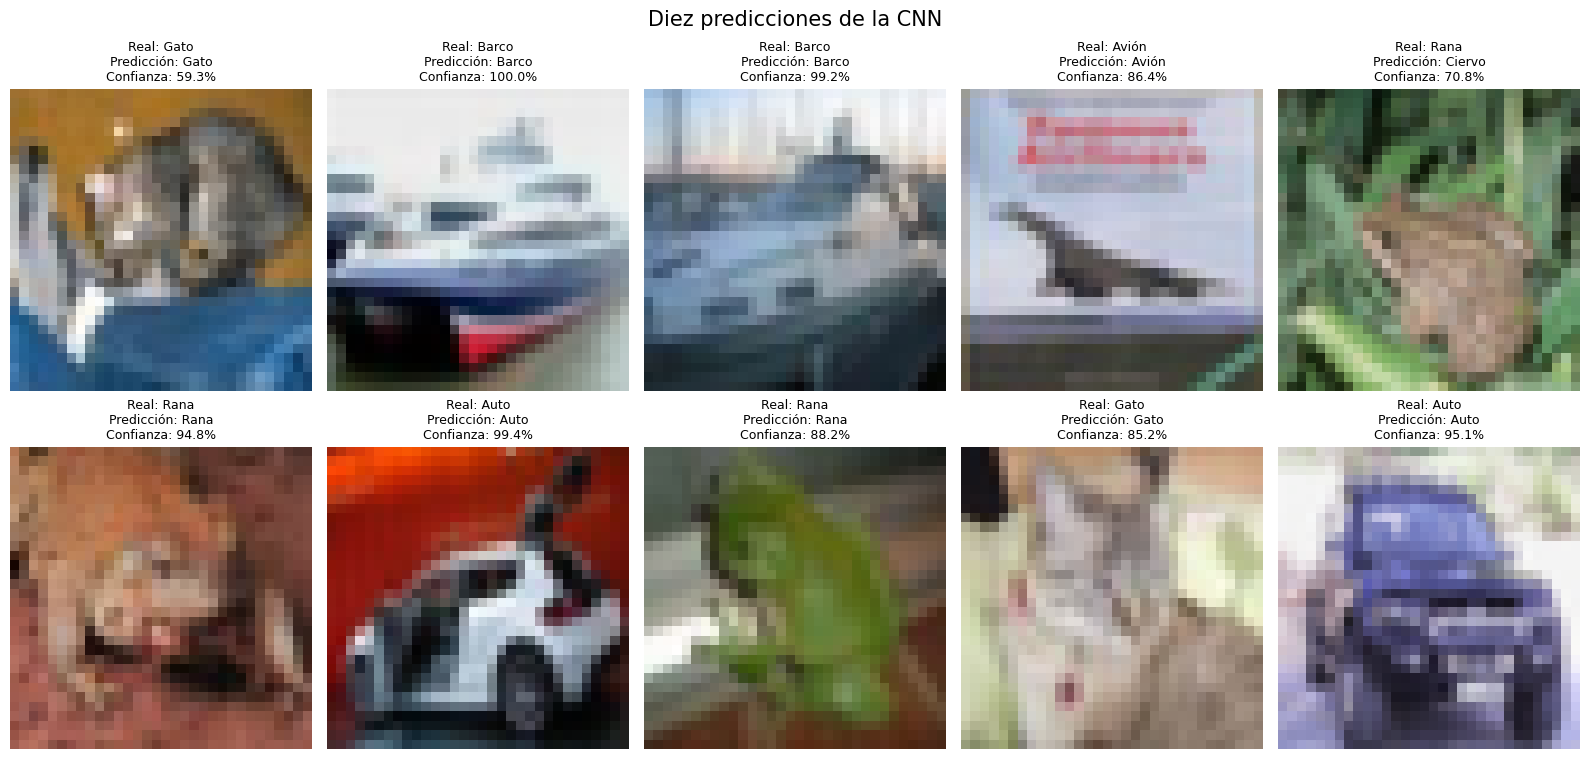

Las diez predicciones se generaron correctamente.


In [12]:
# Mostrar diez imágenes de prueba con sus predicciones

fig, axes = plt.subplots(2, 5, figsize=(16, 8))
axes = axes.flatten()

for i, ax in enumerate(axes):
    imagen = test_images[i]
    clase_real = int(test_labels[i][0])
    clase_predicha = int(predicted_labels[i])
    confianza = float(predictions[i][clase_predicha]) * 100

    ax.imshow(imagen)
    ax.set_title(
        f"Real: {class_names[clase_real]}\n"
        f"Predicción: {class_names[clase_predicha]}\n"
        f"Confianza: {confianza:.1f}%",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle("Diez predicciones de la CNN", fontsize=15)
plt.tight_layout()

plt.savefig(
    "resultados/10_predicciones.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Las diez predicciones se generaron correctamente.")